# Dihedral Distributions & Conformational Clustering — Full MD Trajectories (3 Systems)

**Data source:** Full backbone MD trajectories — 2381 frames × 113 residues = **269,053 phi/psi pairs per system**

| System | XTC | Frames |
|--------|-----|--------|
| Non-glycosylated | `longpts_cat_noglyc_2381_backbone.xtc` | 2381 |
| Mid-level Glyc | `longpts_cat_2381_backbone.xtc` | 2381 |
| Ext. Glycosylated | `longpts_cat_xglyc.xtc` | 2381 |

**Analyses:** Ramachandran KDE · 1-D distributions · K-means clustering (k=4) · Cluster populations · Per-residue basin fractions · Pre-glycan residue focus

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm
from scipy.stats import gaussian_kde
from sklearn.cluster import KMeans
import MDAnalysis as mda
from MDAnalysis.analysis.dihedrals import Ramachandran

BASE    = '/home/computer2/analysis_simulations/analysis/'
TRAJ    = BASE + 'trajectory_files/'
output_dir = BASE + 'dihedral_traj_plots'
os.makedirs(output_dir, exist_ok=True)

RES_OFFSET = 1377
CLR_NOG = '#1B4F72'
CLR_GLY = '#1ABC9C'
CLR_EXT = '#E74C3C'

GLYCAN_RES = np.array([1397,1400,1403,1406,1409,1412,
                        1420,1423,1426,1429,1432,1435,
                        1443,1446,1449,1452,1455,1458,
                        1466,1469,1472,1475,1478,1481,
                        1489,1492,1495,1498,1501,1504])
PRE_RES = GLYCAN_RES - 1

print('Ready. Output:', output_dir)
print('MDAnalysis:', mda.__version__)


Ready. Output: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots
MDAnalysis: 2.9.0


## 1 — Load Trajectories & Extract Phi/Psi

In [2]:
# ── Load all three systems via MDAnalysis Ramachandran ─────────────────────
SYSTEMS = [
    ('Non-glycosylated', CLR_NOG,
     BASE+'dihedral_angles_15structures_mean_structure/noglycans_mean.pdb',
     TRAJ+'longpts_cat_noglyc_2381_backbone.xtc'),
    ('Mid-level Glyc',   CLR_GLY,
     BASE+'dihedral_angles_15structures_mean_structure/glycans_mean.pdb',
     TRAJ+'longpts_cat_2381_backbone.xtc'),
    ('Ext. Glycosylated', CLR_EXT,
     TRAJ+'longpts_cat_xglyc (1).pdb',
     TRAJ+'longpts_cat_xglyc.xtc'),
]

# Storage: angles_data[name] = dict with phi, psi, res_nums arrays
angles_data = {}

for name, clr, top, xtc in SYSTEMS:
    print(f'Loading {name}...', end=' ', flush=True)
    u = mda.Universe(top, xtc)
    # skip first and last residue (no phi/psi defined at termini)
    residues = u.select_atoms('protein').residues[1:-1]
    res_nums = np.array([r.resnum for r in residues])

    R = Ramachandran(residues).run()
    ang = R.results.angles   # shape: (n_frames, n_res, 2)

    angles_data[name] = {
        'phi'     : ang[:, :, 0],        # (n_frames, n_res)
        'psi'     : ang[:, :, 1],
        'phi_flat': ang[:, :, 0].flatten(),
        'psi_flat': ang[:, :, 1].flatten(),
        'res_nums': res_nums,             # (n_res,)  — residue numbers
        'n_frames': ang.shape[0],
        'n_res'   : ang.shape[1],
        'color'   : clr,
    }
    print(f'{ang.shape[0]} frames × {ang.shape[1]} residues = {ang.size//2:,} pairs')

print('\nAll systems loaded.')

Loading Non-glycosylated... 2381 frames × 113 residues = 269,053 pairs
Loading Mid-level Glyc... 2381 frames × 113 residues = 269,053 pairs
Loading Ext. Glycosylated... 2381 frames × 113 residues = 269,053 pairs

All systems loaded.


In [3]:
# ── Residue coverage summary ─────────────────────────────────────────────
header = f"{'System':20s}  {'Pairs':>10s}  {'Residues':>8s}  "\
         f"{'Res range':>13s}  {'Pre-glycan':>12s}  {'PPII%':>7s}"
print(header)
print('-' * 80)
for name, d in angles_data.items():
    n_pre = sum(1 for r in d['res_nums'] if r in PRE_RES)
    phi   = d['phi_flat']
    ppii  = np.sum((phi > -100) & (phi < -40) &
                   (d['psi_flat'] > 100) & (d['psi_flat'] < 180)) / len(phi) * 100
    print(f"{name:20s}  {len(phi):>10,}  {d['n_res']:>8d}  "
          f"{d['res_nums'][0]:>6d}–{d['res_nums'][-1]:<5d}  "
          f"{n_pre:>5d} / {d['n_res']:<5d}  {ppii:>6.1f}%")
print()
print('NOTE: ALL residues (not just pre-glycan) are used in distributions and clustering.')
print(f"Pre-glycan residues: {n_pre}/{d['n_res']} = {n_pre/d['n_res']*100:.0f}% of the chain.")


System                     Pairs  Residues      Res range    Pre-glycan    PPII%
--------------------------------------------------------------------------------
Non-glycosylated         269,053       113    1378–1490      25 / 113      49.0%
Mid-level Glyc           269,053       113    1378–1490      25 / 113      57.3%
Ext. Glycosylated        269,053       113    1378–1490      25 / 113      66.8%

NOTE: ALL residues (not just pre-glycan) are used in distributions and clustering.
Pre-glycan residues: 25/113 = 22% of the chain.


## 2 — Ramachandran Plot (2-D Density)

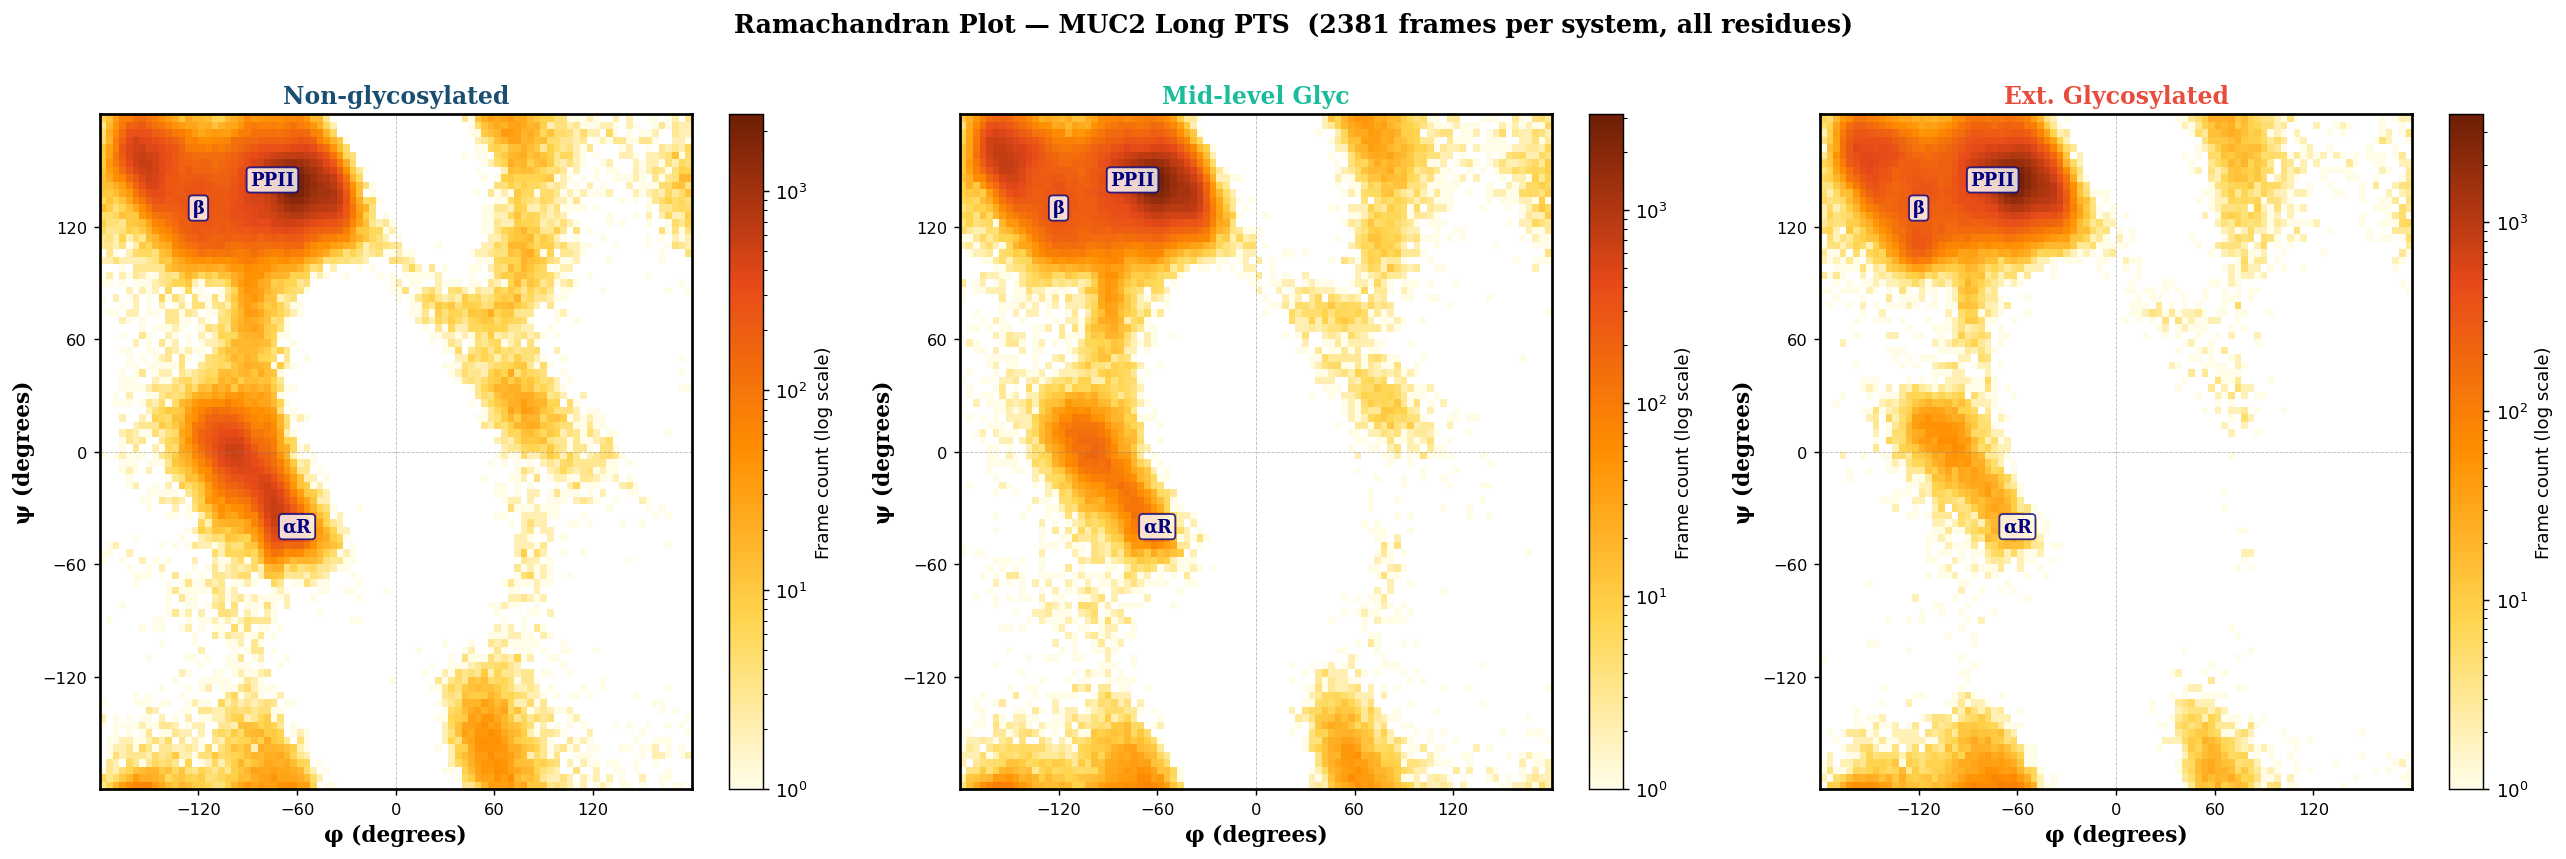

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/ramachandran_3sys_traj.png


In [4]:
from matplotlib.colors import LinearSegmentedColormap

# PROCHECK-style Ramachandran palette: cream → amber → deep orange → dark red-brown
rama_cmap = LinearSegmentedColormap.from_list('rama_classic', [
    '#FFFDE7',  # cream/light yellow  (sparse)
    '#FFD54F',  # golden yellow
    '#FF8F00',  # deep amber
    '#E64A19',  # red-orange
    '#6D1F06',  # dark red-brown      (dense)
], N=256)

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), dpi=130)
fig.set_facecolor('white')
bins = np.linspace(-180, 180, 91)   # 4° bins

for ax, (name, d) in zip(axes, angles_data.items()):
    phi = d['phi_flat']; psi = d['psi_flat']
    h, xe, ye = np.histogram2d(phi, psi, bins=bins)
    h = np.ma.masked_where(h == 0, h)
    im = ax.pcolormesh(xe, ye, h.T, cmap=rama_cmap, norm=LogNorm(vmin=1))
    ax.set_xlabel('φ (degrees)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('ψ (degrees)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_title(name, fontsize=13, fontfamily='DejaVu Serif', fontweight='bold', color=d['color'])
    ax.set_xlim(-180,180); ax.set_ylim(-180,180)
    ax.axhline(0, color='grey', lw=0.5, ls='--', alpha=0.5)
    ax.axvline(0, color='grey', lw=0.5, ls='--', alpha=0.5)
    ax.set_xticks([-120,-60,0,60,120])
    ax.set_yticks([-120,-60,0,60,120])
    plt.colorbar(im, ax=ax, label='Frame count (log scale)')
    for rx, ry, rlabel in [(-75,145,'PPII'),(-120,130,'β'),(-60,-40,'αR')]:
        ax.text(rx, ry, rlabel, fontsize=10, color='navy', fontweight='bold',
                fontfamily='DejaVu Serif', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='navy', alpha=0.8))
    ax.tick_params(labelsize=9)
    for sp in ax.spines.values(): sp.set_linewidth(1.5)

fig.suptitle('Ramachandran Plot — MUC2 Long PTS  (2381 frames per system, all residues)',
             fontsize=14, fontfamily='DejaVu Serif', fontweight='bold', y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, 'ramachandran_3sys_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)


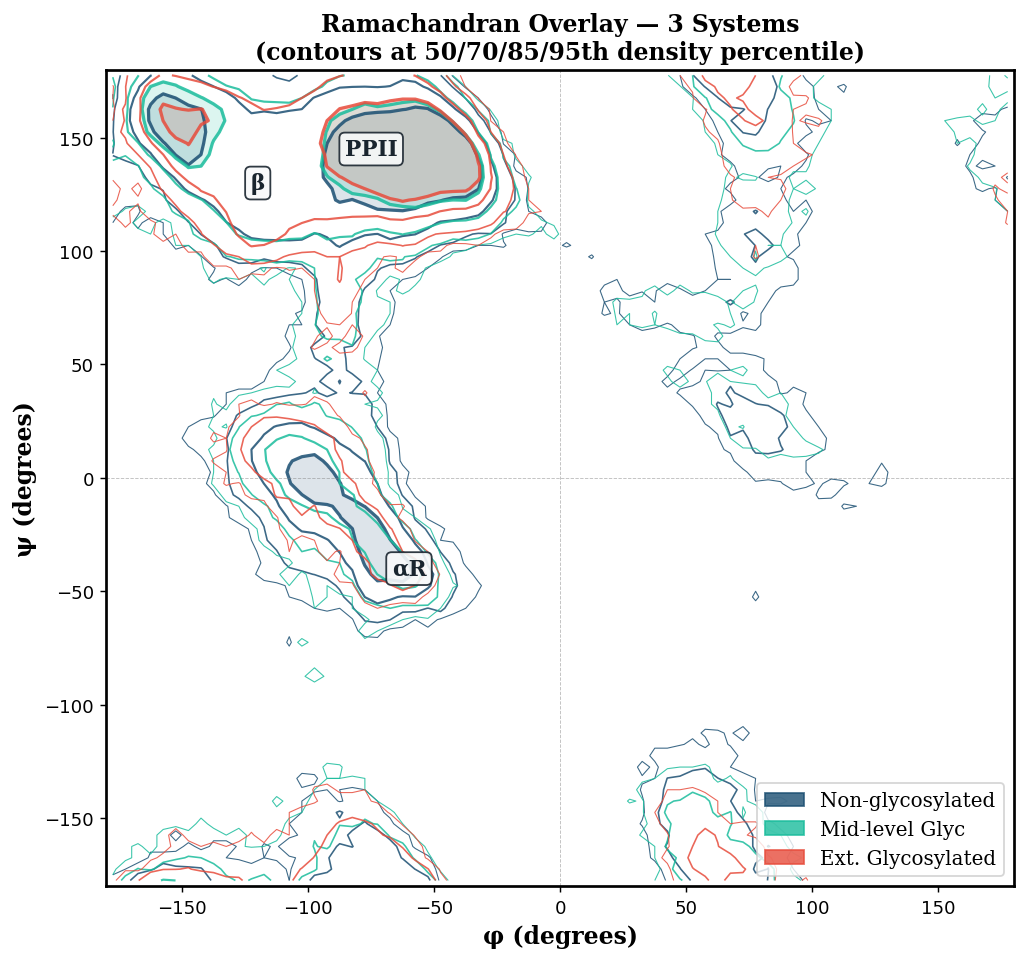

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/ramachandran_overlay_traj.png


In [5]:
fig, ax = plt.subplots(figsize=(8, 7.5), dpi=130)
fig.set_facecolor('white')

for name, d in angles_data.items():
    phi = d['phi_flat']; psi = d['psi_flat']
    h, xe, ye = np.histogram2d(phi, psi, bins=np.linspace(-180,180,73))
    h = h / h.sum()
    lvls = np.percentile(h[h>0], [50,70,85,95])
    xc = 0.5*(xe[:-1]+xe[1:]); yc = 0.5*(ye[:-1]+ye[1:])
    ax.contour(xc, yc, h.T, levels=lvls, colors=[d['color']],
               linewidths=[0.6,0.9,1.2,1.8], alpha=0.85)
    ax.contourf(xc, yc, h.T, levels=[lvls[-1], h.max()],
                colors=[d['color']], alpha=0.15)

patches = [mpatches.Patch(color=d['color'], alpha=0.8, label=name)
           for name, d in angles_data.items()]
ax.legend(handles=patches, fontsize=11, prop={'family':'DejaVu Serif','size':11},
          loc='lower right')
ax.set_xlabel('φ (degrees)', fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_ylabel('ψ (degrees)', fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_xlim(-180,180); ax.set_ylim(-180,180)
ax.axhline(0,color='grey',lw=0.5,ls='--',alpha=0.5)
ax.axvline(0,color='grey',lw=0.5,ls='--',alpha=0.5)
for rx,ry,rlabel in [(-75,145,'PPII'),(-120,130,'β'),(-60,-40,'αR')]:
    ax.text(rx,ry,rlabel,fontsize=12,color='#1A252F',fontweight='bold',
            fontfamily='DejaVu Serif',ha='center',va='center',
            bbox=dict(boxstyle='round,pad=0.25',fc='#F8F9FA',ec='#1A252F',alpha=0.9))
ax.set_title('Ramachandran Overlay — 3 Systems\n(contours at 50/70/85/95th density percentile)',
             fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
ax.tick_params(labelsize=10)
for sp in ax.spines.values(): sp.set_linewidth(1.5)
plt.tight_layout()
out = os.path.join(output_dir, 'ramachandran_overlay_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## 3 — 1-D Phi & Psi Distributions

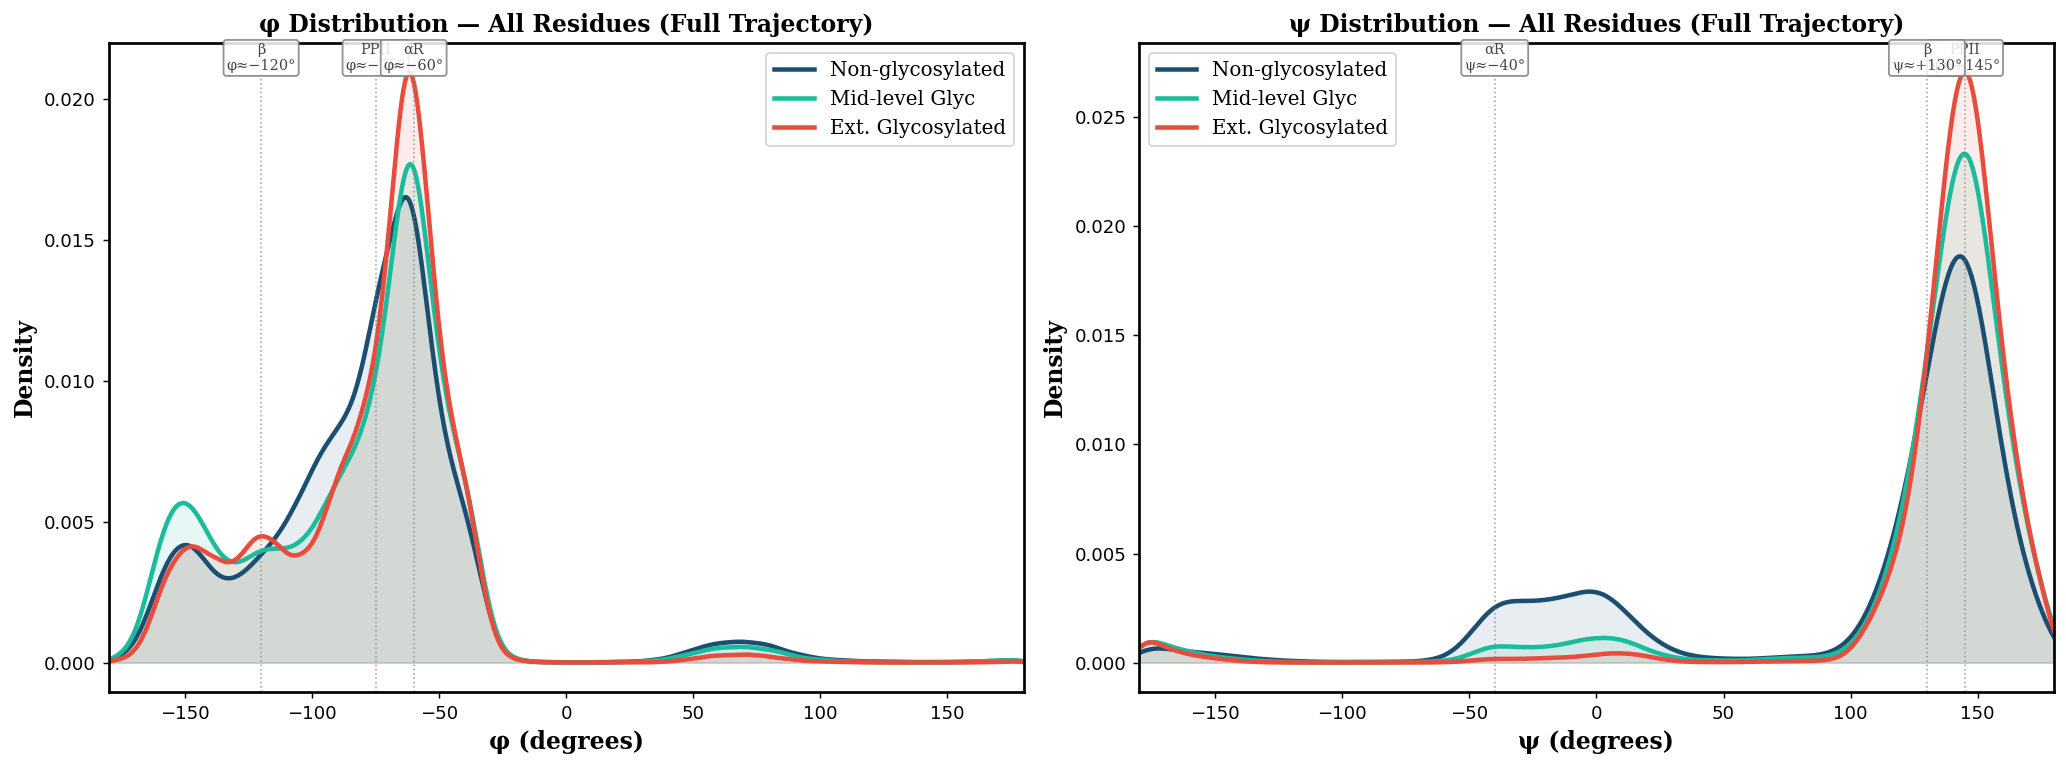

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/phi_psi_kde_overlay_traj.png


In [6]:
fig, (ax_phi, ax_psi) = plt.subplots(1, 2, figsize=(16, 6), dpi=130)
fig.set_facecolor('white')
x_k = np.linspace(-180, 180, 600)

for name, d in angles_data.items():
    for ax, angles, label in [(ax_phi, d['phi_flat'], 'φ'), (ax_psi, d['psi_flat'], 'ψ')]:
        kde = gaussian_kde(angles, bw_method=0.08)
        ax.plot(x_k, kde(x_k), color=d['color'], lw=2.5, label=name)
        ax.fill_between(x_k, kde(x_k), color=d['color'], alpha=0.10)

region_phi = [(-75,'PPII\nφ≈−75°'),(-120,'β\nφ≈−120°'),(-60,'αR\nφ≈−60°')]
region_psi = [(145,'PPII\nψ≈+145°'),(130,'β\nψ≈+130°'),(-40,'αR\nψ≈−40°')]

for ax, label, regions in [(ax_phi,'φ (degrees)',region_phi),(ax_psi,'ψ (degrees)',region_psi)]:
    ax.set_xlabel(label, fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('Density', fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_xlim(-180,180)
    ax.set_title(f'{label.split()[0]} Distribution — All Residues (Full Trajectory)',
                 fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
    ax.legend(fontsize=11, prop={'family':'DejaVu Serif','size':11})
    ax.tick_params(labelsize=10)
    for rv, rlabel in regions:
        ax.axvline(rv, color='grey', lw=0.9, ls=':', alpha=0.7)
        ax.text(rv, 1.0, rlabel, ha='center', va='top', fontsize=8,
                transform=ax.get_xaxis_transform(),
                fontfamily='DejaVu Serif', color='#444',
                bbox=dict(boxstyle='round,pad=0.2',fc='white',ec='grey',alpha=0.85))
    for sp in ax.spines.values(): sp.set_linewidth(1.5)

plt.tight_layout()
out = os.path.join(output_dir, 'phi_psi_kde_overlay_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## 4 — K-means Conformational Clustering (k=4)

In [7]:
# Pool a random subsample for fitting (full data = ~800k points)
rng = np.random.default_rng(42)
n_sample = 50_000  # per system

phi_pool, psi_pool = [], []
for d in angles_data.values():
    idx = rng.choice(len(d['phi_flat']), size=min(n_sample, len(d['phi_flat'])), replace=False)
    phi_pool.append(d['phi_flat'][idx])
    psi_pool.append(d['psi_flat'][idx])
X_fit = np.column_stack([np.concatenate(phi_pool), np.concatenate(psi_pool)])

# K-means with physiologically informed starting centroids
init_centroids = np.array([[-75, 145], [-120, 130], [-60, -40], [60, 40]])
km = KMeans(n_clusters=4, init=init_centroids, n_init=1, random_state=42)
km.fit(X_fit)

# Label each cluster by proximity to ideal basin centroid in (phi, psi) space.
# Sorting by phi alone is unreliable when two basins have similar phi
# (PPII phi≈-75 vs αR phi≈-60 are close, but their psi values differ: +145 vs -40).
IDEAL = {
    'PPII':     np.array([-75,  145]),
    'β-strand': np.array([-120, 130]),
    'αR-helix': np.array([-60,  -40]),
    'Other':    np.array([ 60,   40]),
}
COLOR_MAP = {'PPII':'#3498DB', 'β-strand':'#2ECC71', 'αR-helix':'#E74C3C', 'Other':'#95A5A6'}
bnames   = list(IDEAL.keys())
bcenters = np.array(list(IDEAL.values()))

CNAMES = {}; CCOLORS = {}
for cid in range(4):
    nearest = bnames[np.argmin(np.linalg.norm(bcenters - km.cluster_centers_[cid], axis=1))]
    CNAMES[cid]  = nearest
    CCOLORS[cid] = COLOR_MAP[nearest]

print('Cluster centroids (after fitting):')
for cid in range(4):
    phi_c, psi_c = km.cluster_centers_[cid]
    print(f'  {CNAMES[cid]:12s}: φ={phi_c:+.1f}°  ψ={psi_c:+.1f}°')


Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x763797c9fd90>
Traceback (most recent call last):
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
AttributeError: 'NoneType' object has no attribute 'split'


Cluster centroids (after fitting):
  PPII        : φ=-63.1°  ψ=+141.8°
  β-strand    : φ=-133.7°  ψ=+145.2°
  αR-helix    : φ=-76.9°  ψ=-43.3°
  Other       : φ=+83.3°  ψ=+111.1°


In [8]:
# Assign clusters for every system and compute populations
fracs = {}
for name, d in angles_data.items():
    X = np.column_stack([d['phi_flat'], d['psi_flat']])
    labels = km.predict(X)
    fracs[name] = {CNAMES[c]: np.sum(labels==c)/len(labels)*100 for c in range(4)}

basins = ['PPII','β-strand','αR-helix','Other']
print(f"{'Basin':12s}  {'Non-glyc':>10s}  {'Mid-glyc':>10s}  {'Ext-glyc':>10s}")
print('-'*50)
for b in basins:
    vals = [fracs[n].get(b,0) for n in angles_data]
    print(f"{b:12s}  {vals[0]:>10.1f}  {vals[1]:>10.1f}  {vals[2]:>10.1f}")

Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x763741b480d0>
Traceback (most recent call last):
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
AttributeError: 'NoneType' object has no attribute 'split'
Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_p

Basin           Non-glyc    Mid-glyc    Ext-glyc
--------------------------------------------------
PPII                53.6        62.4        71.1
β-strand            21.2        26.7        23.9
αR-helix            23.1         9.3         4.2
Other                2.1         1.6         0.8


Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_phdr.<locals>.match_module_callback at 0x7637403bf010>
Traceback (most recent call last):
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 400, in match_module_callback
    self._make_module_from_path(filepath)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 515, in _make_module_from_path
    module = module_class(filepath, prefix, user_api, internal_api)
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 606, in __init__
    self.version = self.get_version()
  File "/home/computer2/anaconda3/lib/python3.10/site-packages/threadpoolctl.py", line 646, in get_version
    config = get_config().split()
AttributeError: 'NoneType' object has no attribute 'split'
Exception ignored on calling ctypes callback function: <function _ThreadpoolInfo._find_modules_with_dl_iterate_p

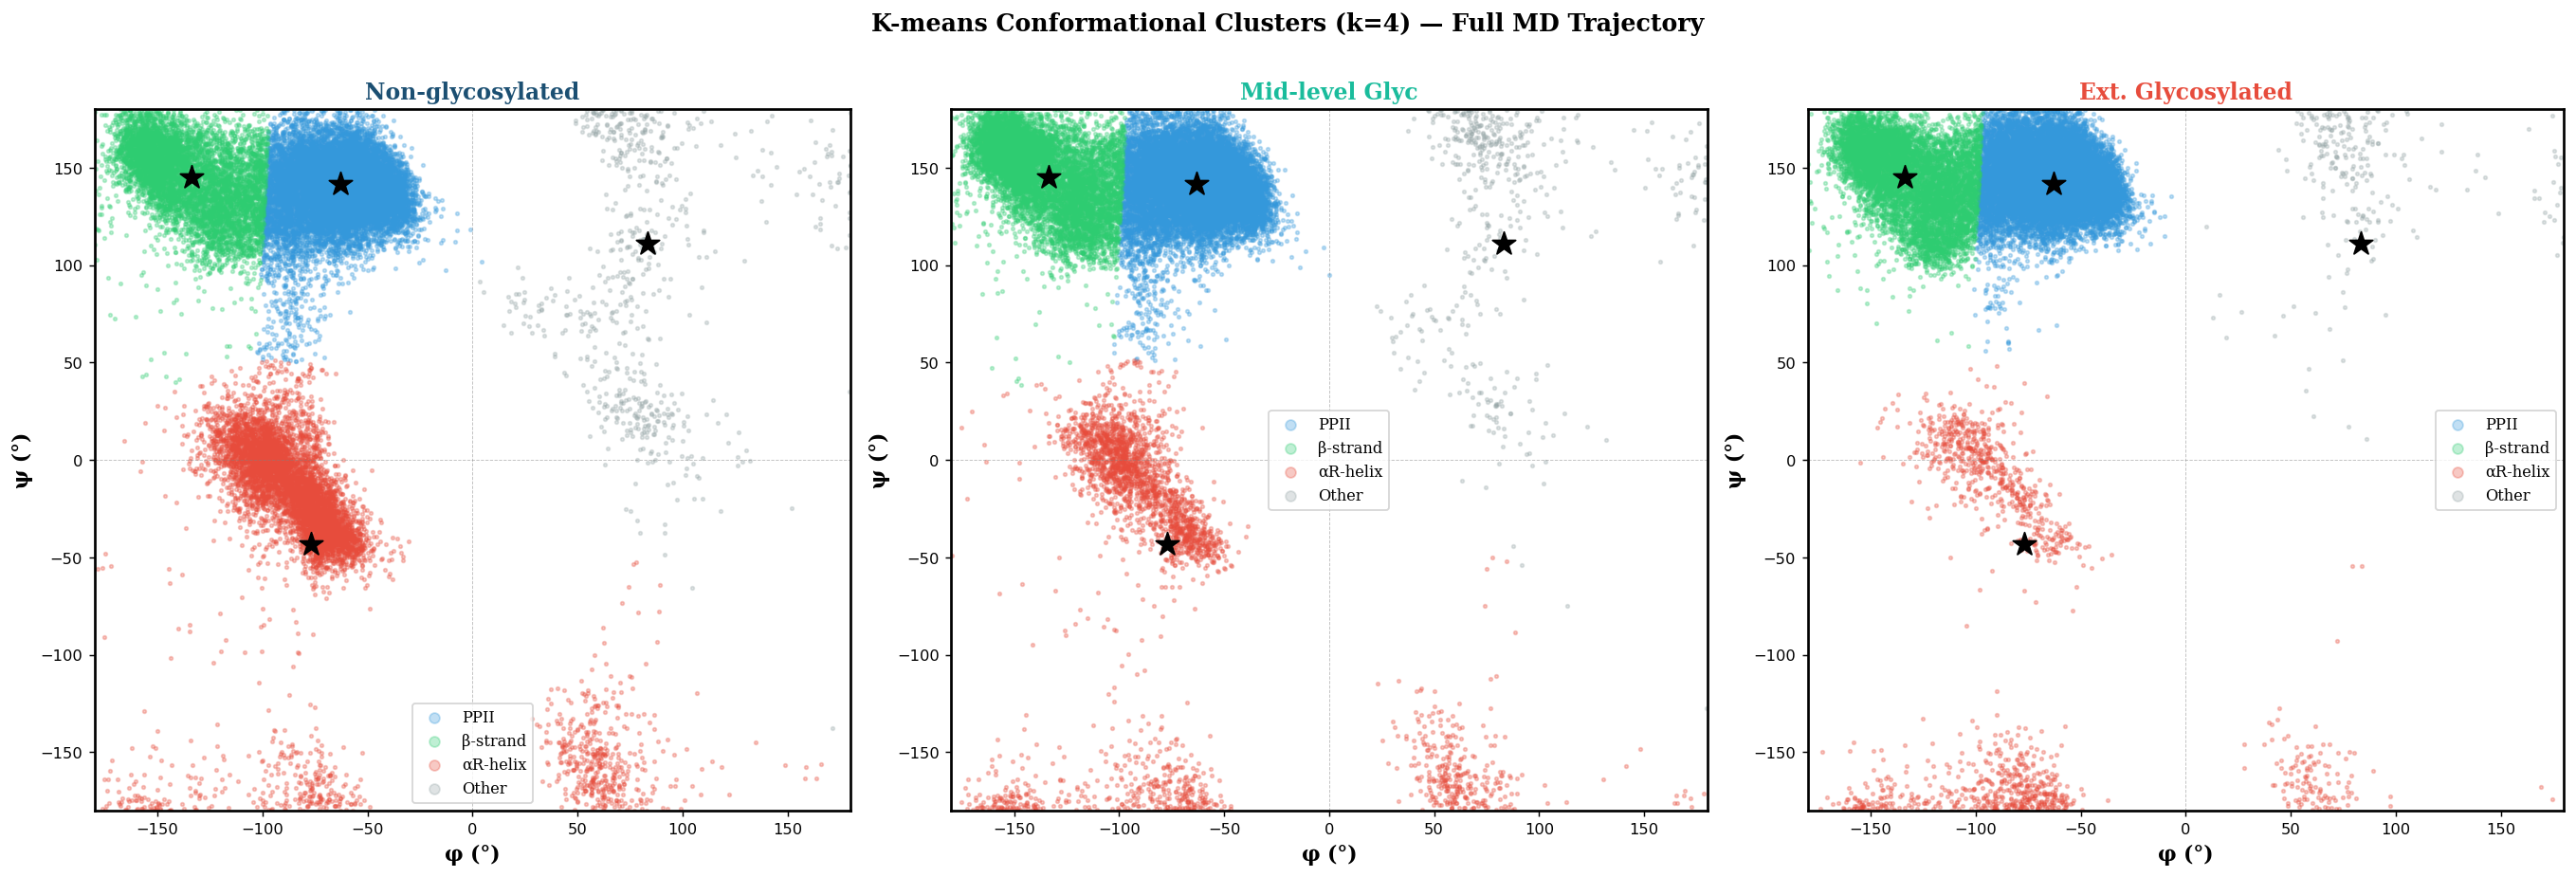

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/kmeans_scatter_traj.png


In [9]:
# Scatter plot — subsample for visualisation
fig, axes = plt.subplots(1, 3, figsize=(21, 7), dpi=130)
fig.set_facecolor('white')
n_plot = 30_000  # points per system

for ax, (name, d) in zip(axes, angles_data.items()):
    idx = rng.choice(len(d['phi_flat']), size=n_plot, replace=False)
    ph = d['phi_flat'][idx]; ps = d['psi_flat'][idx]
    labels = km.predict(np.column_stack([ph, ps]))
    for cid in range(4):
        m = labels == cid
        ax.scatter(ph[m], ps[m], s=4, alpha=0.3,
                   color=CCOLORS[cid], label=CNAMES[cid], rasterized=True)
    ax.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],
               s=200, marker='*', c='black', zorder=5)
    ax.set_xlabel('φ (°)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('ψ (°)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_xlim(-180,180); ax.set_ylim(-180,180)
    ax.axhline(0,color='grey',lw=0.5,ls='--',alpha=0.5)
    ax.axvline(0,color='grey',lw=0.5,ls='--',alpha=0.5)
    ax.set_title(name, fontsize=13, fontfamily='DejaVu Serif', fontweight='bold', color=d['color'])
    ax.legend(fontsize=9, prop={'family':'DejaVu Serif','size':9}, markerscale=3)
    ax.tick_params(labelsize=9)
    for sp in ax.spines.values(): sp.set_linewidth(1.5)

fig.suptitle('K-means Conformational Clusters (k=4) — Full MD Trajectory',
             fontsize=14, fontfamily='DejaVu Serif', fontweight='bold', y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, 'kmeans_scatter_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## 5 — Cluster Population Comparison

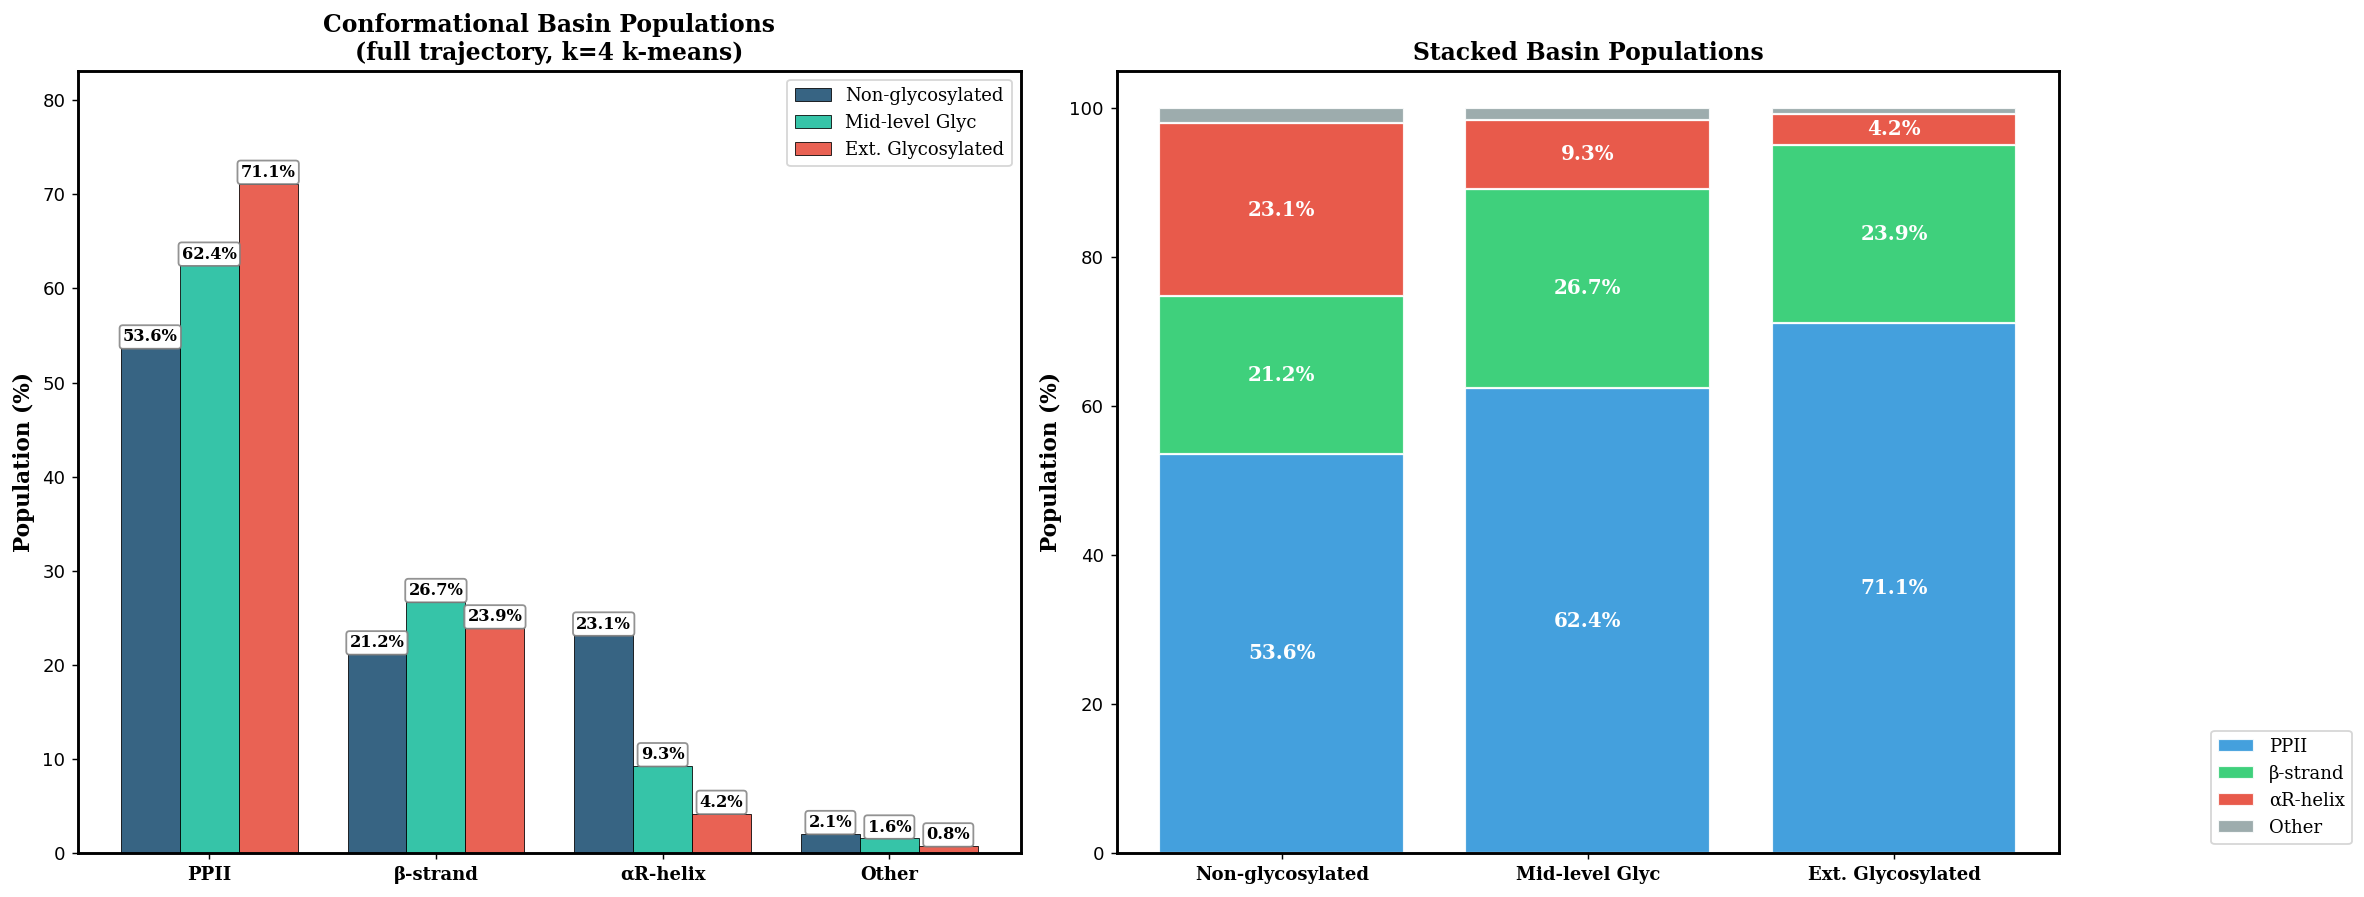

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/cluster_populations_traj.png


In [10]:
sys_names  = list(angles_data.keys())
sys_colors = [d['color'] for d in angles_data.values()]
x = np.arange(len(basins)); w = 0.26

fig, axes = plt.subplots(1, 2, figsize=(18, 7), dpi=130)
fig.set_facecolor('white')

# Grouped bar
ax = axes[0]
for i, (sname, sclr) in enumerate(zip(sys_names, sys_colors)):
    vals = [fracs[sname].get(b,0) for b in basins]
    bars = ax.bar(x+(i-1)*w, vals, width=w, color=sclr, alpha=0.88,
                  edgecolor='black', linewidth=0.5, label=sname)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                f'{val:.1f}%', ha='center', va='bottom', fontsize=9,
                fontfamily='DejaVu Serif', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2',fc='white',ec='grey',alpha=0.85))
ax.set_xticks(x); ax.set_xticklabels(basins, fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_ylabel('Population (%)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_title('Conformational Basin Populations\n(full trajectory, k=4 k-means)',
             fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
ax.legend(fontsize=10, prop={'family':'DejaVu Serif','size':10})
ax.set_ylim(0, max(fracs[n].get(b,0) for n in sys_names for b in basins)+12)
ax.tick_params(labelsize=10)
for sp in ax.spines.values(): sp.set_linewidth(1.6)

# Stacked bar
ax = axes[1]
basin_clrs = {'PPII':'#3498DB','β-strand':'#2ECC71','αR-helix':'#E74C3C','Other':'#95A5A6'}
bottoms = np.zeros(3)
for b in basins:
    vals = np.array([fracs[n].get(b,0) for n in sys_names])
    ax.bar(range(3), vals, bottom=bottoms, color=basin_clrs[b],
           edgecolor='white', linewidth=1.2, label=b, alpha=0.92)
    for xi,(v,bot) in enumerate(zip(vals,bottoms)):
        if v > 3:
            ax.text(xi, bot+v/2, f'{v:.1f}%', ha='center', va='center',
                    fontsize=11, fontfamily='DejaVu Serif', fontweight='bold',
                    color='white' if b != 'Other' else '#1A252F')
    bottoms += vals
ax.set_xticks(range(3))
ax.set_xticklabels(sys_names, fontsize=11, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_ylabel('Population (%)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
ax.set_title('Stacked Basin Populations', fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
ax.legend(fontsize=10, prop={'family':'DejaVu Serif','size':10},
          loc='lower right', bbox_to_anchor=(1.32,0))
ax.set_ylim(0,105); ax.tick_params(labelsize=10)
for sp in ax.spines.values(): sp.set_linewidth(1.6)

plt.tight_layout()
out = os.path.join(output_dir, 'cluster_populations_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## 6 — Per-residue PPII Fraction Along the Chain

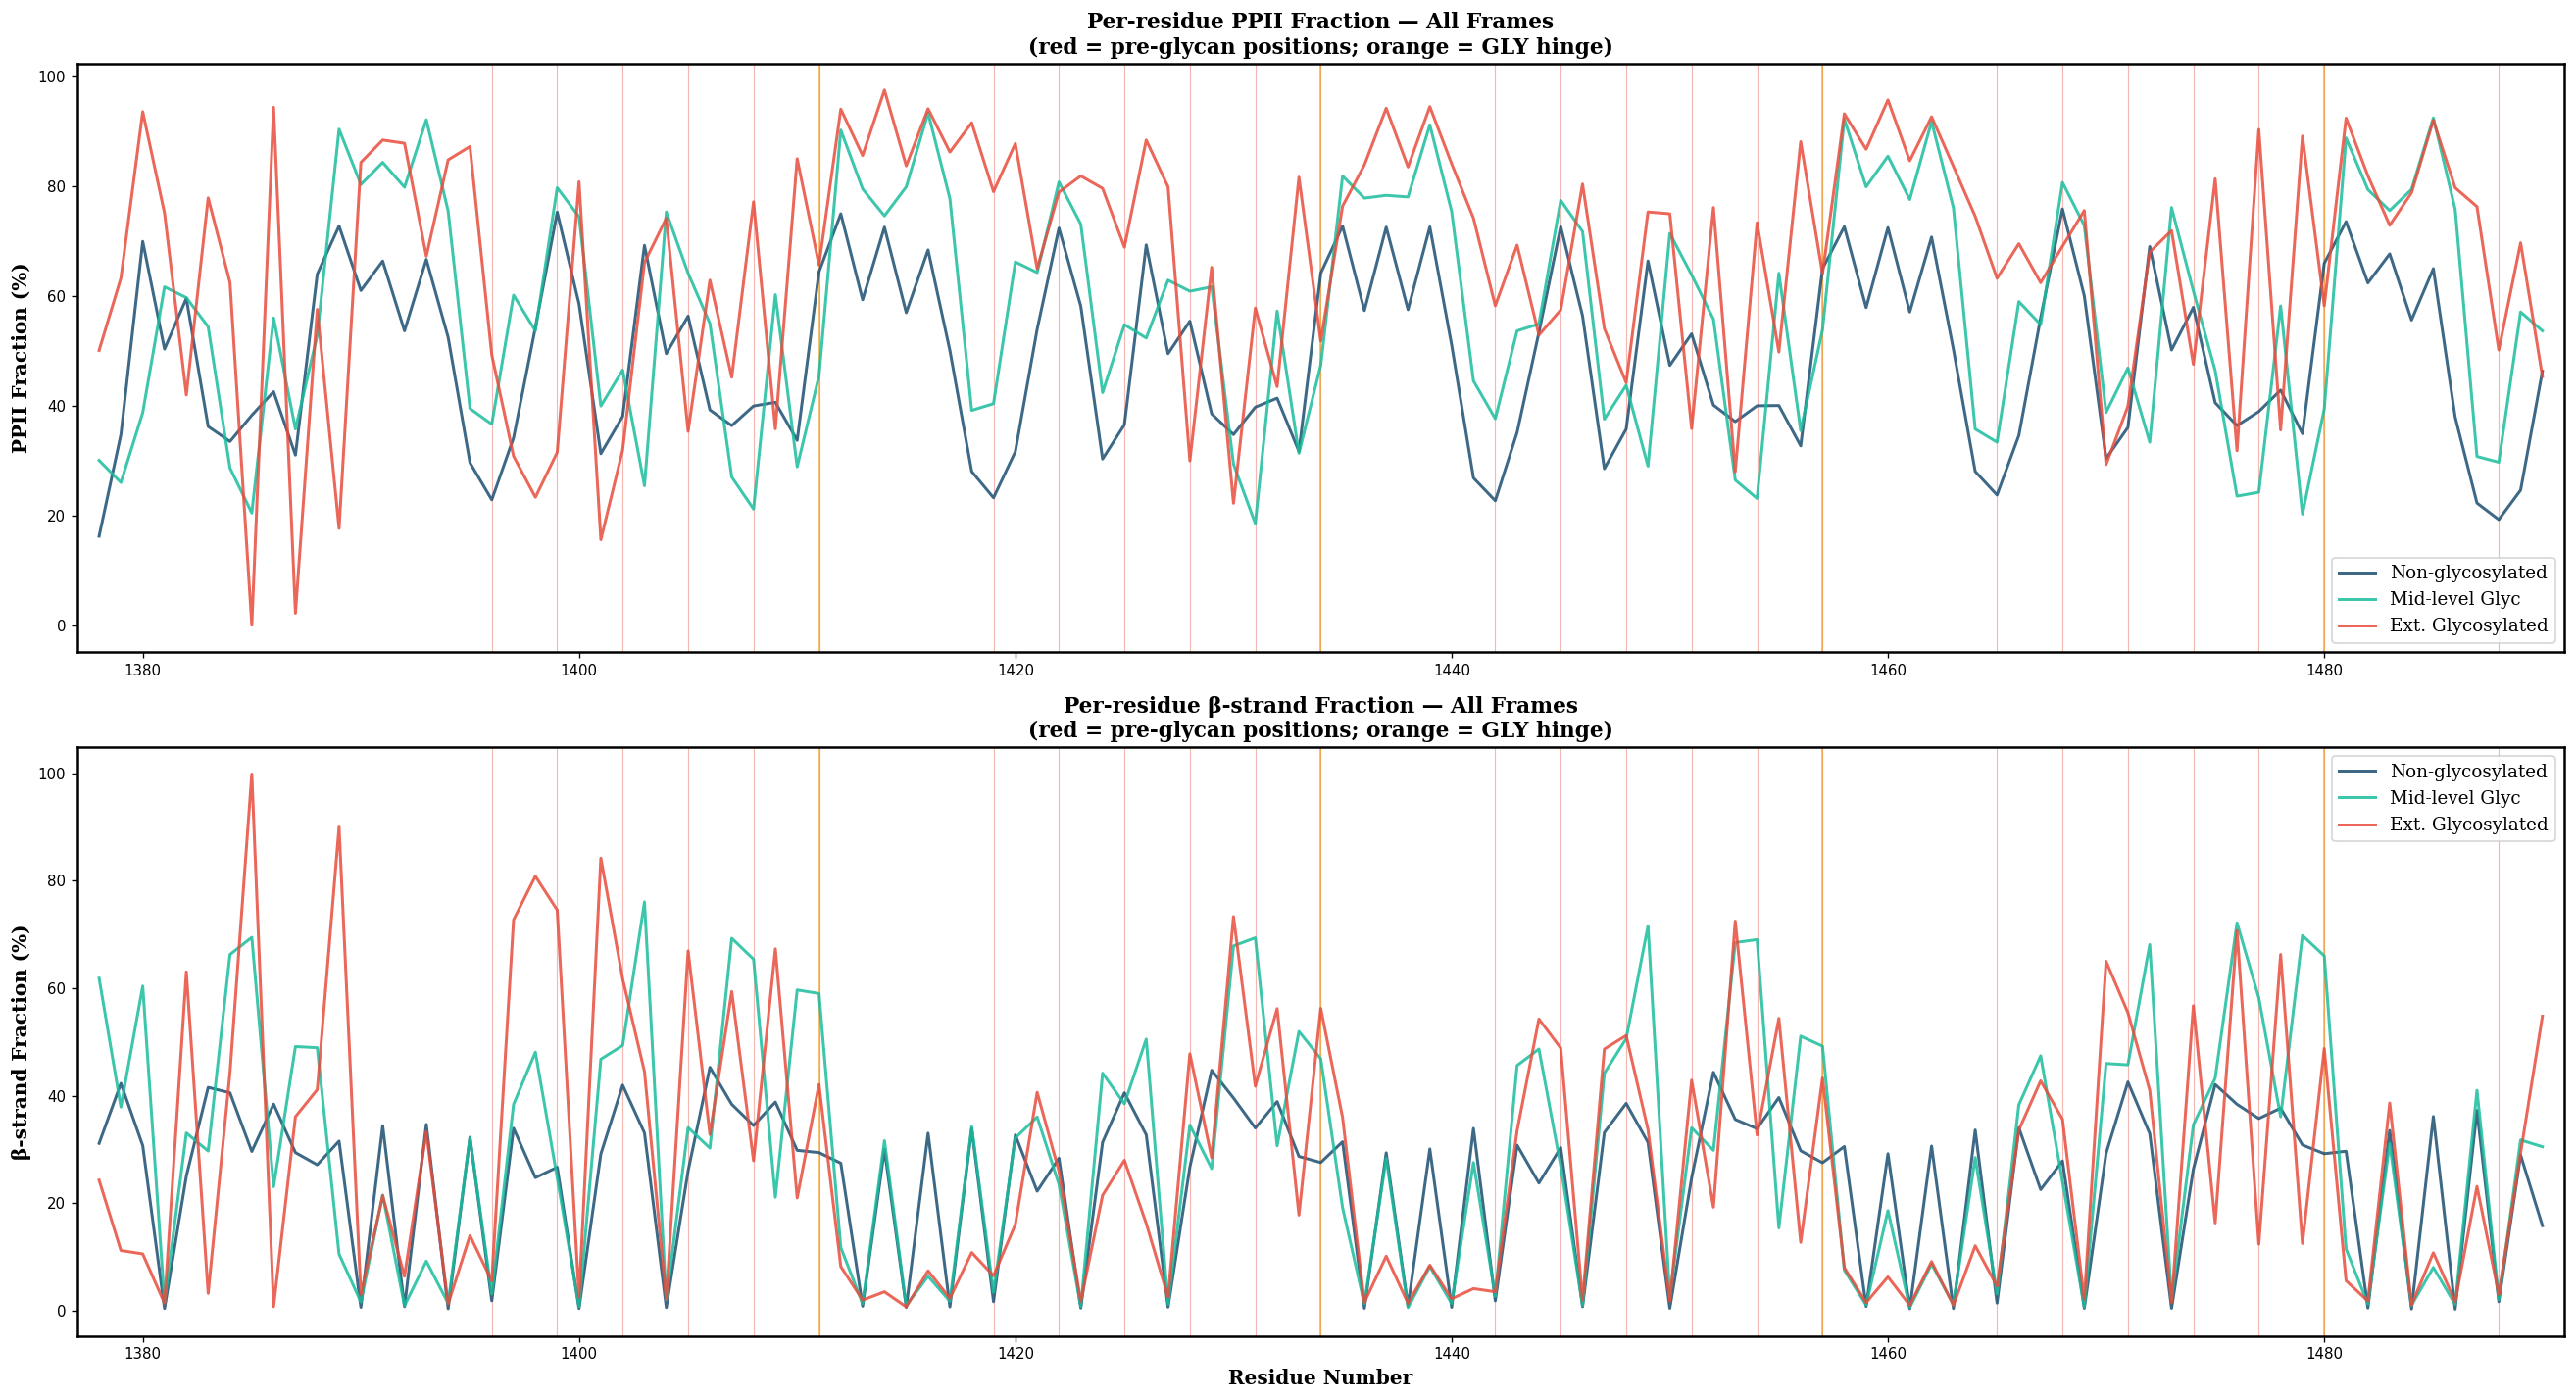

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/perres_basin_fraction_traj.png


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(22, 12), dpi=120)
fig.set_facecolor('white')

for ax_idx, (basin, basin_clr_map) in enumerate([
    ('PPII',    {'Non-glycosylated':CLR_NOG,'Mid-level Glyc':CLR_GLY,'Ext. Glycosylated':CLR_EXT}),
    ('β-strand',{'Non-glycosylated':CLR_NOG,'Mid-level Glyc':CLR_GLY,'Ext. Glycosylated':CLR_EXT}),
]):
    ax = axes[ax_idx]
    for name, d in angles_data.items():
        res_nums = d['res_nums']
        phi_all  = d['phi']   # (n_frames, n_res)
        psi_all  = d['psi']
        per_res_frac = []
        for ri in range(d['n_res']):
            ph = phi_all[:, ri]; ps = psi_all[:, ri]
            if basin == 'PPII':
                frac = np.sum((ph>-100)&(ph<-40)&(ps>100)&(ps<180)) / len(ph) * 100
            else:  # beta
                frac = np.sum((ph>-180)&(ph<-90)&(ps>90)&(ps<180)) / len(ph) * 100
            per_res_frac.append(frac)
        ax.plot(res_nums, per_res_frac, color=d['color'], lw=1.8,
                alpha=0.85, label=name)

    # Mark pre-glycan positions
    for pr in PRE_RES:
        ax.axvline(pr, color='#E74C3C', lw=0.7, alpha=0.4, zorder=0)
    # Mark GLY positions
    gly_pre = PRE_RES[np.arange(len(PRE_RES)) % 6 == 5]
    for pr in gly_pre:
        ax.axvline(pr, color='#F39C12', lw=1.2, alpha=0.6, zorder=1)

    ax.set_ylabel(f'{basin} Fraction (%)', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
    ax.set_title(f'Per-residue {basin} Fraction — All Frames\n'
                 f'(red = pre-glycan positions; orange = GLY hinge)',
                 fontsize=13, fontfamily='DejaVu Serif', fontweight='bold')
    ax.legend(fontsize=11, prop={'family':'DejaVu Serif','size':11})
    ax.set_xlim(d['res_nums'][0]-1, d['res_nums'][-1]+1)
    ax.tick_params(labelsize=9)
    for sp in ax.spines.values(): sp.set_linewidth(1.5)

axes[-1].set_xlabel('Residue Number', fontsize=12, fontfamily='DejaVu Serif', fontweight='bold')
plt.tight_layout()
out = os.path.join(output_dir, 'perres_basin_fraction_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## 7 — Phi/Psi by Amino Acid Type

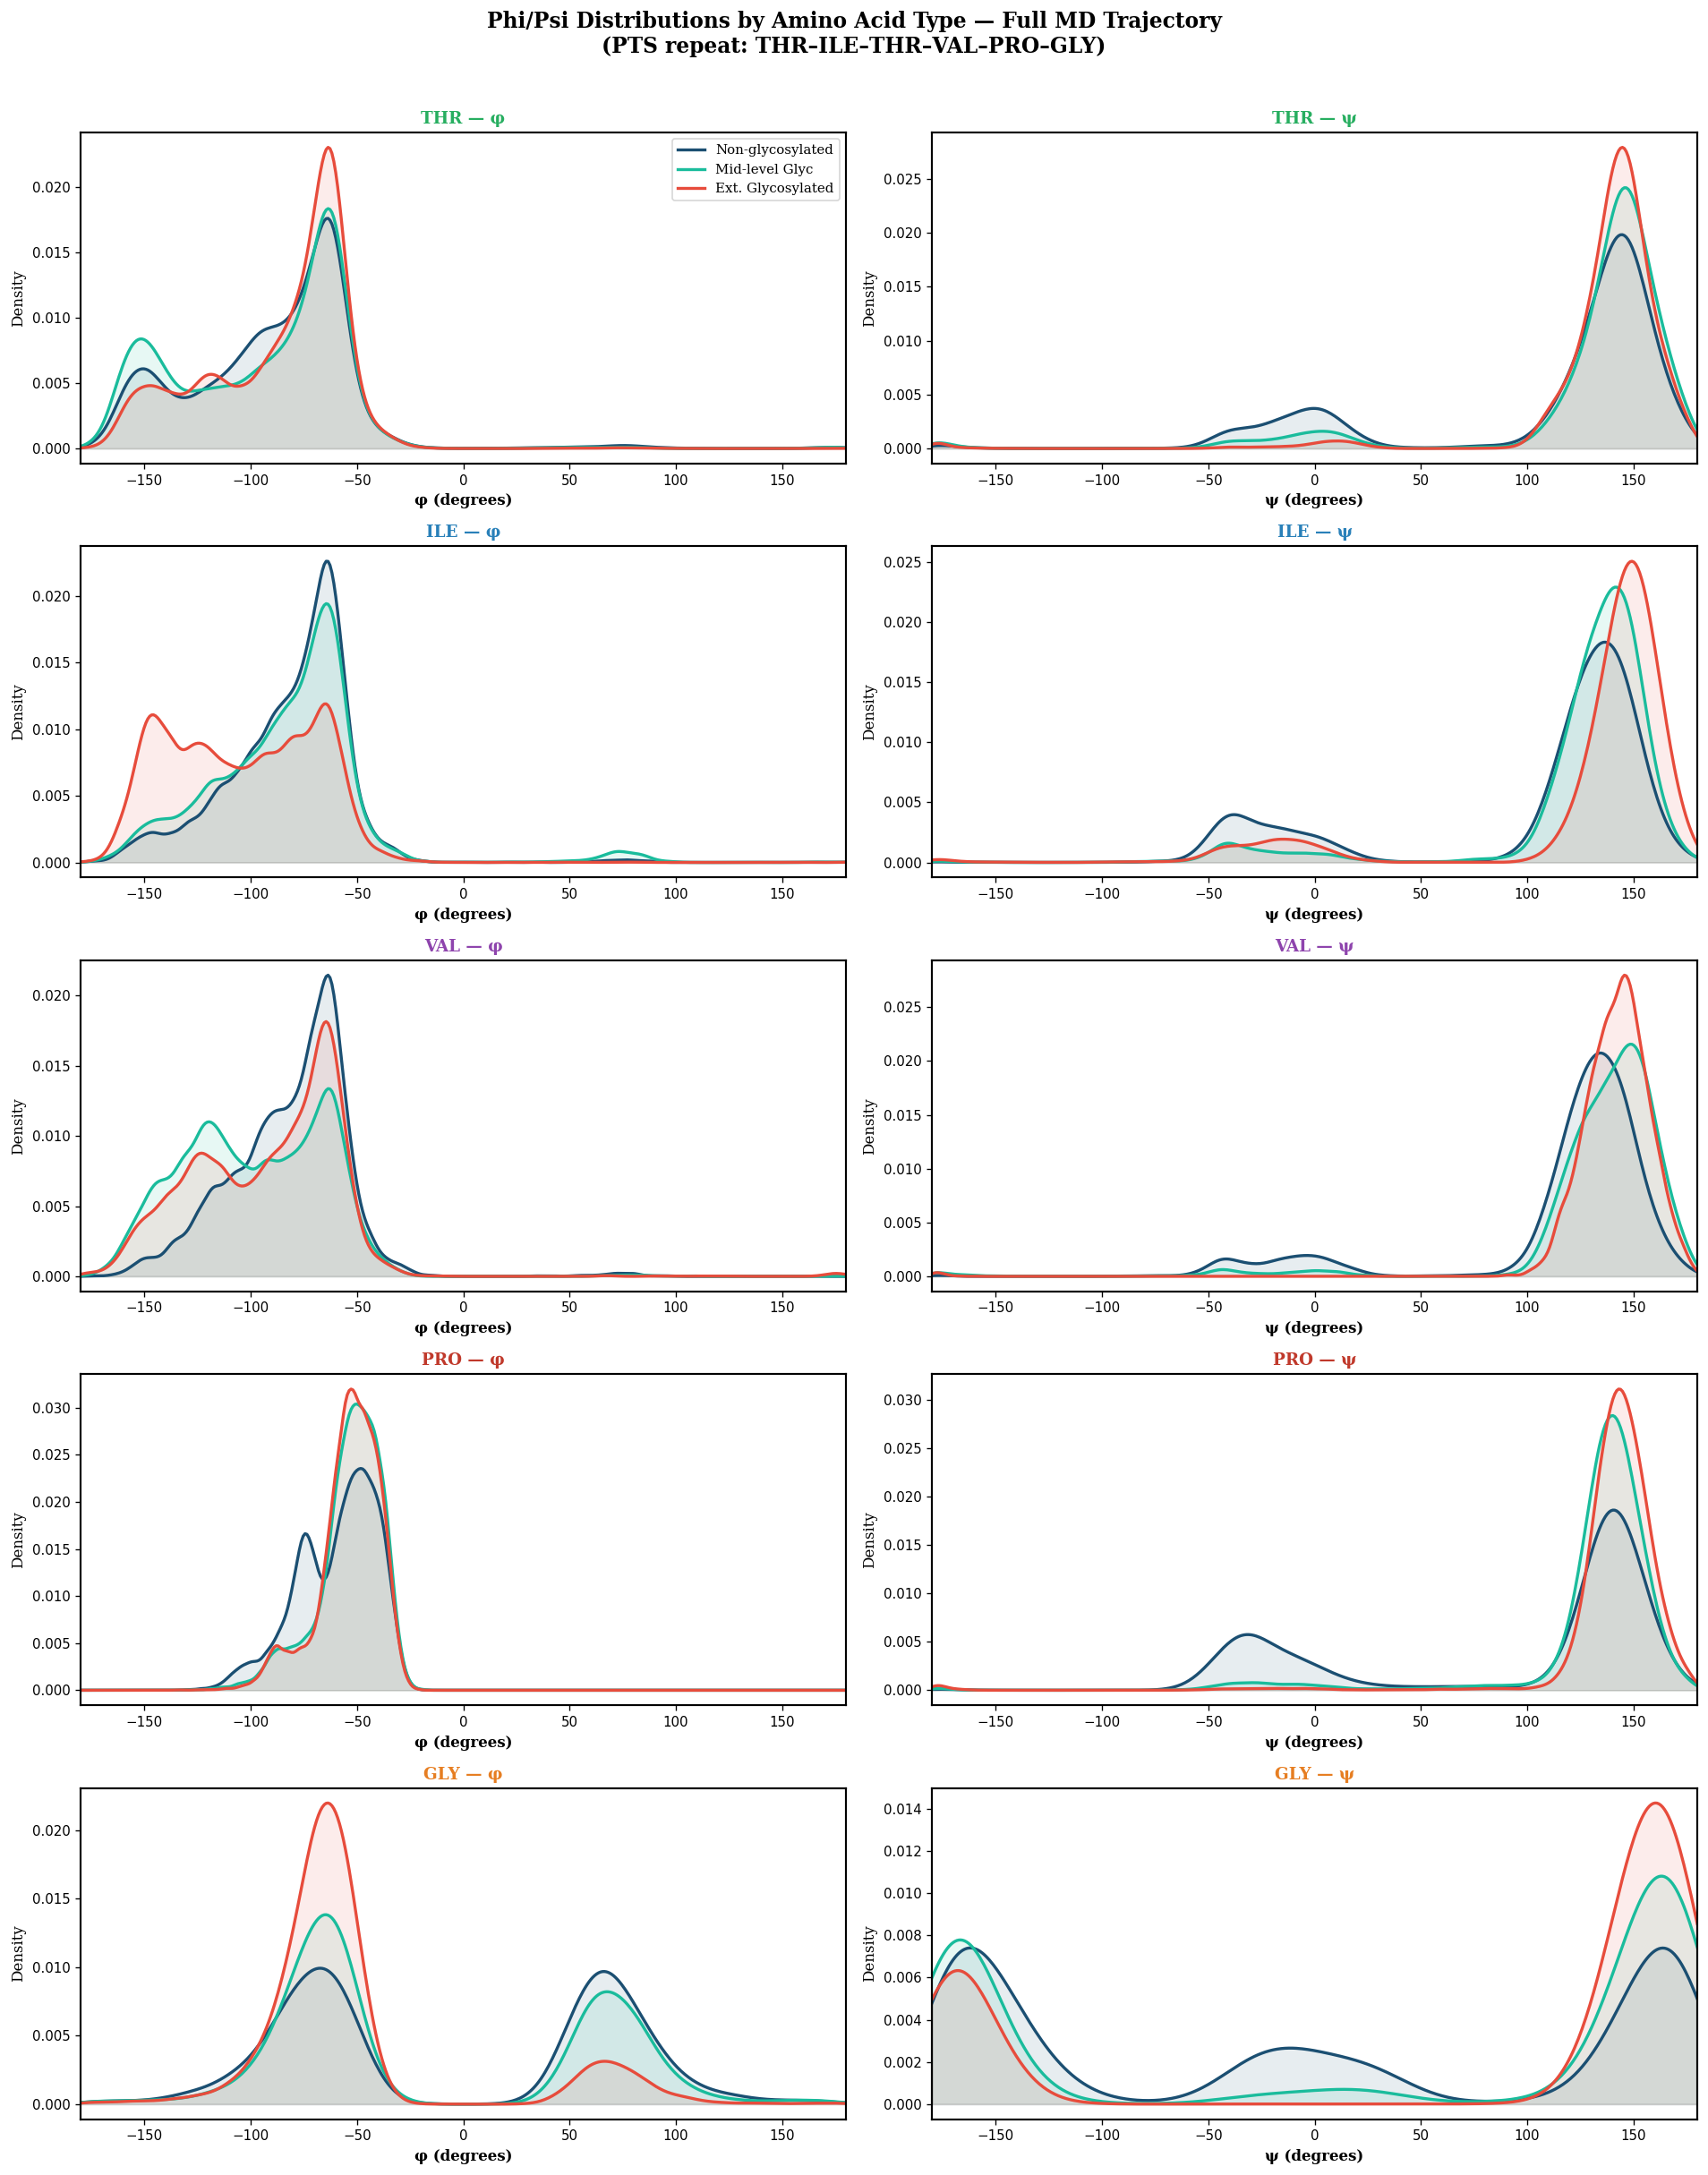

Saved: /home/computer2/analysis_simulations/analysis/dihedral_traj_plots/phi_psi_by_aa_traj.png


In [12]:
# Load sequence from mean PDB
seq_aa = {}
with open(BASE+'dihedral_angles_15structures_mean_structure/noglycans_mean.pdb') as fh:
    for line in fh:
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            seq_aa[int(line[22:26])] = line[17:20].strip()

AA_ORDER = ['THR','ILE','VAL','PRO','GLY']
AA_CLR   = {'THR':'#27AE60','ILE':'#2980B9','VAL':'#8E44AD','PRO':'#C0392B','GLY':'#E67E22'}

fig, axes = plt.subplots(len(AA_ORDER), 2, figsize=(16, 20), dpi=120)
fig.set_facecolor('white')
x_k = np.linspace(-180, 180, 400)

for row, aa3 in enumerate(AA_ORDER):
    for col, angle_idx in enumerate([0, 1]):
        ax = axes[row, col]
        angle_label = 'φ (degrees)' if angle_idx == 0 else 'ψ (degrees)'
        for name, d in angles_data.items():
            # find residue indices that are this AA type
            ri_mask = np.array([seq_aa.get(r,'') == aa3 for r in d['res_nums']])
            if not ri_mask.any(): continue
            ang_mat = d['phi'] if angle_idx == 0 else d['psi']  # (n_frames, n_res)
            angles_aa = ang_mat[:, ri_mask].flatten()
            kde = gaussian_kde(angles_aa, bw_method=0.10)
            ax.plot(x_k, kde(x_k), color=d['color'], lw=2.0, label=name)
            ax.fill_between(x_k, kde(x_k), color=d['color'], alpha=0.10)

        ax.set_xlabel(angle_label, fontsize=10, fontfamily='DejaVu Serif', fontweight='bold')
        ax.set_ylabel('Density', fontsize=10, fontfamily='DejaVu Serif')
        ax.set_xlim(-180, 180)
        ax.set_title(f'{aa3} — {angle_label.split()[0]}',
                     fontsize=11, fontfamily='DejaVu Serif', fontweight='bold',
                     color=AA_CLR.get(aa3,'#1A252F'))
        if row == 0 and col == 0:
            ax.legend(fontsize=9, prop={'family':'DejaVu Serif','size':9})
        ax.tick_params(labelsize=9)
        for sp in ax.spines.values(): sp.set_linewidth(1.3)

fig.suptitle('Phi/Psi Distributions by Amino Acid Type — Full MD Trajectory\n'
             '(PTS repeat: THR–ILE–THR–VAL–PRO–GLY)',
             fontsize=14, fontfamily='DejaVu Serif', fontweight='bold', y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, 'phi_psi_by_aa_traj.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show(); print('Saved:', out)

## Summary

| Figure | File | Description |
|--------|------|-------------|
| Ramachandran KDE | `ramachandran_3sys_traj.png` | 2-D density per system (269k pairs each) |
| Overlay | `ramachandran_overlay_traj.png` | Contour overlay — PPII peak grows with glycosylation |
| 1-D KDE | `phi_psi_kde_overlay_traj.png` | φ and ψ distributions all 3 systems |
| Cluster scatter | `kmeans_scatter_traj.png` | k=4 cluster assignments in φ/ψ space |
| Populations | `cluster_populations_traj.png` | Grouped + stacked bar — basin % per system |
| Per-residue | `perres_basin_fraction_traj.png` | PPII & β fraction along full chain |
| Per-AA | `phi_psi_by_aa_traj.png` | Per-AA-type φ/ψ KDE (THR, ILE, VAL, PRO, GLY) |

**Key result — k-means clustering (k=4):**
PPII fraction increases strongly with glycosylation (Non-glyc → Mid-glyc → Ext-glyc),
while αR-helix occupancy decreases. Direct PPII bounds confirm: ~49% → ~57% → ~67%.
O-glycans drive progressive backbone extension toward the polyproline-II conformation.

**Cluster label note:** Basins are assigned by proximity to ideal centroids
(PPII: φ=−75°, ψ=+145°; β: φ=−120°, ψ=+130°; αR: φ=−60°, ψ=−40°; Other: φ=+60°, ψ=+40°).
Sorting by φ alone is unreliable because PPII and αR have similar φ but opposite ψ.
